# Current-Fed vs Voltage-Fed Axisymmetric Inductor

Build one inductor with the high-level `model.build_concentric_model` factory and a selected core material. First solve it with an imposed current, then use the magnitude of its induced terminal voltage as the voltage-fed excitation. Both results share the same component, mesh, and material model so their winding/core losses and apparent inductance can be compared. All geometry lengths are in metres.

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import materialdatabase as mdb
import numpy as np
import pandas as pd
from pymagfem import fem, model

repository_root = Path.cwd().resolve()
if not (repository_root / "pyproject.toml").is_file():
    repository_root = repository_root.parent
simulation_dir = repository_root / "notebooks" / "sim"
simulation_dir.mkdir(parents=True, exist_ok=True)

## 1. Select the core material

Set `CORE_MODEL` to `"N49"` for measured nonlinear material data or `"custom_linear"` for the user-defined linear core. The notebook runs both current-fed and voltage-fed cases in sequence for the selected material.

In [11]:
# Select the core material model.
CORE_MODEL = "N49"  # "N49" or "custom_linear"

FREQUENCY_HZ = 300_000.0
CURRENT_A = 4.0
CORE_TEMPERATURE_C = 60.0
COPPER_TEMPERATURE_C = 60.0
USE_LITZ = False
LITZ_NUMBER_STRANDS = 150
LITZ_STRAND_DIAMETER_M = 200e-6
MESH_SIZE_M = 0.0008

CORE_RELATIVE_PERMEABILITY = 1500.0
CORE_LOSS_ANGLE_DEG = 5.0
CORE_CONDUCTIVITY_S_PER_M = 0.6
CORE_RELATIVE_PERMITTIVITY = 100_000.0
CORE_PERMITTIVITY_LOSS_ANGLE_DEG = 25.0

if CORE_MODEL not in {"N49", "custom_linear"}:
    raise ValueError("CORE_MODEL must be 'N49' or 'custom_linear'")

copper_conductivity_s_per_m = fem.copper_conductivity_at_temperature_s_per_m(
    COPPER_TEMPERATURE_C
)
core_material = model.Material(
    "core",
    relative_permeability=CORE_RELATIVE_PERMEABILITY,
    permeability_loss_angle_deg=CORE_LOSS_ANGLE_DEG,
    conductivity=CORE_CONDUCTIVITY_S_PER_M,
    relative_permittivity=CORE_RELATIVE_PERMITTIVITY,
    permittivity_loss_angle_deg=CORE_PERMITTIVITY_LOSS_ANGLE_DEG,
    properties={"temperature_c": CORE_TEMPERATURE_C},
)
nonlinear_materials = None
if CORE_MODEL == "N49":
    material_data = mdb.Data()
    n49_material = mdb.Material.N49
    n49_permeability = material_data.get_complex_permeability(
        material=n49_material,
        data_source=mdb.DataSource.LEA_MTB,
        pv_fit_function=mdb.FitFunction.enhancedSteinmetz,
    )
    n49_permittivity = material_data.get_complex_permittivity(
        material=n49_material,
        data_source=mdb.DataSource.LEA_MTB,
    )
    n49_core_material = fem.material_from_materialdatabase(
        n49_permeability,
        n49_permittivity,
        frequency=FREQUENCY_HZ,
        temperature=CORE_TEMPERATURE_C,
    )
    nonlinear_materials = {"core": n49_core_material}

center_leg_radius_m = 0.00745
core_area_m2 = np.pi * center_leg_radius_m**2
conductor = model.RoundConductor(
    "round_copper",
    radius=0.0013,
    material="copper",
    construction="litz" if USE_LITZ else "solid",
    strands=LITZ_NUMBER_STRANDS if USE_LITZ else None,
    strand_diameter=LITZ_STRAND_DIAMETER_M if USE_LITZ else None,
)
component = model.build_concentric_model(
    core_area=core_area_m2,
    windings=(
        model.RadialWindingSpec(
            "primary",
            conductor,
            turns=14,
            radial_columns=2,
            current=CURRENT_A,
        ),
    ),
    insulation=model.InsulationSpec(
        c2w_left=0.003,
        c2w_right=0.00235,
        c2w_top=0.0073,
        c2w_bottom=0.0005,
        w2w=0.0005,
    ),
    air_gap_length=0.0005,
    name="14-turn example inductor",
)
component.materials = [
    core_material,
    model.Material("air"),
    model.Material("copper", conductivity=copper_conductivity_s_per_m),
]
component.excitation.frequency = FREQUENCY_HZ
component.excitation.circuits = {"primary": CURRENT_A}

print(f"Core model: {CORE_MODEL}")
print(f"Copper conductivity: {copper_conductivity_s_per_m / 1e6:.2f} MS/m")

Core model: N49
Copper conductivity: 50.12 MS/m


## 2. Create one shared mesh

The current-fed and voltage-fed runs use the same component, material definitions, and mesh. This isolates excitation mode as the comparison variable.

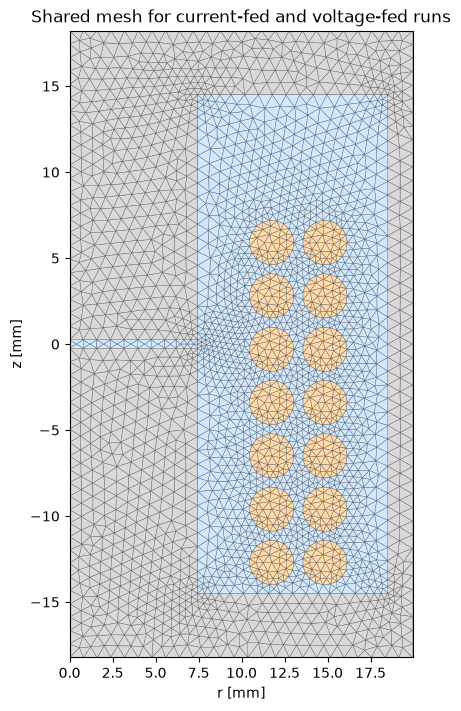

In [12]:
simulation = fem.FrequencyDomainSimulation(component)
mesh = simulation.create_mesh(max_size=MESH_SIZE_M)

fig_mesh, ax_mesh = plt.subplots(figsize=(10, 7), constrained_layout=True)
fem.plot_mesh(mesh, ax=ax_mesh)
ax_mesh.set_title("Shared mesh for current-fed and voltage-fed runs")
plt.show()

## 3. Current-fed reference case

Drive the component with the selected terminal current. Record the resulting induced terminal-voltage phasor; its magnitude will become the voltage-fed target. Save the current-fed result before changing excitation.

In [13]:
current_result = simulation.solve(nonlinear_materials=nonlinear_materials)
current_terminal_voltages = current_result.winding_terminal_voltages()
induced_voltage_v = current_terminal_voltages["primary"]
voltage_excitation_v = abs(induced_voltage_v)
current_terminal_currents = current_result.model.excitation.circuits
current_flux_linkages_wb = current_result.winding_flux_linkages()
current_losses_w = current_result.loss_summary()

print(f"Frequency: {FREQUENCY_HZ:,.0f} Hz")
print(f"Core model: {CORE_MODEL}")
print(f"Current-fed primary current: {abs(current_terminal_currents['primary']):.4f} A peak")
print(
    "Current-fed induced primary voltage: "
    f"{abs(induced_voltage_v):.4f} V peak "
    f"at {np.angle(induced_voltage_v, deg=True):.2f} deg"
)
print(f"Current-fed primary flux linkage: {abs(current_flux_linkages_wb['primary']):.6g} Wb-turn")
print(f"Current-fed losses: {current_losses_w}")
print(f"Voltage-fed target magnitude: {voltage_excitation_v:.4f} V peak")

current_report = current_result.report()
current_report.print()
current_result_json = simulation_dir / f"inductor_{CORE_MODEL}_current-fed_result.json"
current_report.write_json(current_result_json)
print(f"Saved current-fed report: {current_result_json}")

Nonlinear solve: starting (15 max iterations)
Nonlinear solve: iteration 1/15, relative error=1.000e+00, elapsed=0.59s, iteration=0.59s
Nonlinear solve: iteration 2/15, relative error=1.528e-01, elapsed=0.82s, iteration=0.23s
Nonlinear solve: iteration 3/15, relative error=2.578e-02, elapsed=1.08s, iteration=0.26s
Nonlinear solve: iteration 4/15, relative error=4.521e-03, elapsed=1.45s, iteration=0.37s
Nonlinear solve converged in 4 iterations
Frequency: 300,000 Hz
Core model: N49
Current-fed primary current: 4.0000 A peak
Current-fed induced primary voltage: 690.1266 V peak at 89.13 deg
Current-fed primary flux linkage: 0.000366147 Wb-turn
Current-fed losses: {'primary_copper': 2.7137063091226468, 'primary_transport': 2.7137063091226468, 'primary_proximity': 0.0, 'core_magnetic': 14.711548787389447, 'core_electrical': 0.7885888188392411, 'total': 18.213843915351333}
Voltage-fed target magnitude: 690.1266 V peak
Frequency: 300,000 Hz
Current primary: 4.000 A
Mesh: 2563 nodes, 4981 tria

## 4. Voltage-fed reproduction

Use the magnitude of the current-fed induced terminal voltage as the applied voltage. The same `simulation` instance reuses its component and mesh; the voltage solver adjusts current until this terminal-voltage target is met. The phasor reference changes, so compare current and inductance consistently using magnitudes and the ratio of flux linkage to current.

In [14]:
voltage_result = simulation.solve_voltage(
    voltage_excitation_v,
    winding="primary",
    nonlinear_materials=nonlinear_materials,
)
voltage_terminal_voltages = voltage_result.winding_terminal_voltages()
voltage_terminal_currents = voltage_result.model.excitation.circuits
voltage_flux_linkages_wb = voltage_result.winding_flux_linkages()
voltage_losses_w = voltage_result.loss_summary()

print(f"Voltage-fed target: {voltage_excitation_v:.4f} V peak")
print(f"Voltage-fed primary current: {abs(voltage_terminal_currents['primary']):.4f} A peak")
print(f"Voltage-fed primary terminal voltage: {abs(voltage_terminal_voltages['primary']):.4f} V peak")
print(f"Voltage-fed primary flux linkage: {abs(voltage_flux_linkages_wb['primary']):.6g} Wb-turn")
print(f"Voltage-fed losses: {voltage_losses_w}")

voltage_report = voltage_result.report()
voltage_report.print()
voltage_result_json = simulation_dir / f"inductor_{CORE_MODEL}_voltage-fed_result.json"
voltage_report.write_json(voltage_result_json)
print(f"Saved voltage-fed report: {voltage_result_json}")

Nonlinear solve: starting (15 max iterations)
Nonlinear solve: iteration 1/15, relative error=1.000e+00, elapsed=0.14s, iteration=0.14s
Nonlinear solve: iteration 2/15, relative error=1.528e-01, elapsed=0.25s, iteration=0.11s
Nonlinear solve: iteration 3/15, relative error=2.578e-02, elapsed=0.36s, iteration=0.12s
Nonlinear solve: iteration 4/15, relative error=4.521e-03, elapsed=0.48s, iteration=0.12s
Nonlinear solve converged in 4 iterations
Nonlinear solve: starting (15 max iterations)
Nonlinear solve: iteration 1/15, relative error=1.000e+00, elapsed=0.14s, iteration=0.14s
Nonlinear solve: iteration 2/15, relative error=1.496e-01, elapsed=0.26s, iteration=0.12s
Nonlinear solve: iteration 3/15, relative error=2.504e-02, elapsed=0.37s, iteration=0.11s
Nonlinear solve: iteration 4/15, relative error=4.427e-03, elapsed=0.48s, iteration=0.11s
Nonlinear solve converged in 4 iterations
Nonlinear solve: starting (15 max iterations)
Nonlinear solve: iteration 1/15, relative error=1.000e+00,

## 5. Compare the operating points

For each result, apparent inductance is calculated from terminal flux linkage divided by that run's terminal current phasor. The table reports winding and core loss components, total loss, and complex inductance in a common winding reference. The voltage-fed phase reference differs, so compare current and voltage magnitudes and the resulting inductance.

In [17]:
def summarize_operating_point(solved_result):
    primary_current_a = complex(solved_result.model.excitation.circuits["primary"])
    primary_voltage_v = solved_result.winding_terminal_voltages()["primary"]
    primary_flux_linkage_wb = solved_result.winding_flux_linkages()["primary"]
    apparent_inductance_h = primary_flux_linkage_wb / primary_current_a
    primary_winding_loss_w = solved_result.winding_losses()["primary"].total
    core_magnetic_loss_w, core_electrical_loss_w, core_total_loss_w = (
        solved_result.core_losses()
    )
    return {
        "primary_current_peak_a": abs(primary_current_a),
        "primary_terminal_voltage_peak_v": abs(primary_voltage_v),
        "primary_winding_loss_w": primary_winding_loss_w,
        "core_magnetic_loss_w": core_magnetic_loss_w,
        "core_electrical_loss_w": core_electrical_loss_w,
        "core_total_loss_w": core_total_loss_w,
        "total_loss_w": solved_result.loss_summary()["total"],
        "inductance_real_uH": apparent_inductance_h.real * 1e6,
        "inductance_imaginary_uH": apparent_inductance_h.imag * 1e6,
        "inductance_magnitude_uH": abs(apparent_inductance_h) * 1e6,
        "inductance_phase_deg": np.angle(apparent_inductance_h, deg=True),
    }


current_fed_metrics = summarize_operating_point(current_result)
voltage_fed_metrics = summarize_operating_point(voltage_result)
comparison_table = pd.DataFrame({
    "current-fed": current_fed_metrics,
    "voltage-fed": voltage_fed_metrics,
})
comparison_table["difference (voltage - current)"] = (
    comparison_table["voltage-fed"] - comparison_table["current-fed"]
)
print(f"Voltage target from current-fed result: {voltage_excitation_v:.4f} V peak")
print(comparison_table.to_string(float_format=lambda value: f"{value:.6g}"))

Voltage target from current-fed result: 690.1266 V peak
                                 current-fed  voltage-fed  difference (voltage - current)
primary_current_peak_a                     4      3.99757                     -0.00242853
primary_terminal_voltage_peak_v      690.127      689.702                        -0.42498
primary_winding_loss_w               2.71371      2.71037                     -0.00333411
core_magnetic_loss_w                 14.7115      14.6849                        -0.02669
core_electrical_loss_w              0.788589     0.787613                    -0.000975348
core_total_loss_w                    15.5001      15.4725                      -0.0276654
total_loss_w                         18.2138      18.1828                      -0.0309995
inductance_real_uH                   91.5262      91.5254                    -0.000785121
inductance_imaginary_uH             -1.39257     -1.39197                     0.000592318
inductance_magnitude_uH              91.5368

## 6. Inspect the voltage-fed fields

The final plots show the solved field magnitudes for the voltage-fed result. The numerical comparison above remains the source for current-fed versus voltage-fed losses and inductance.

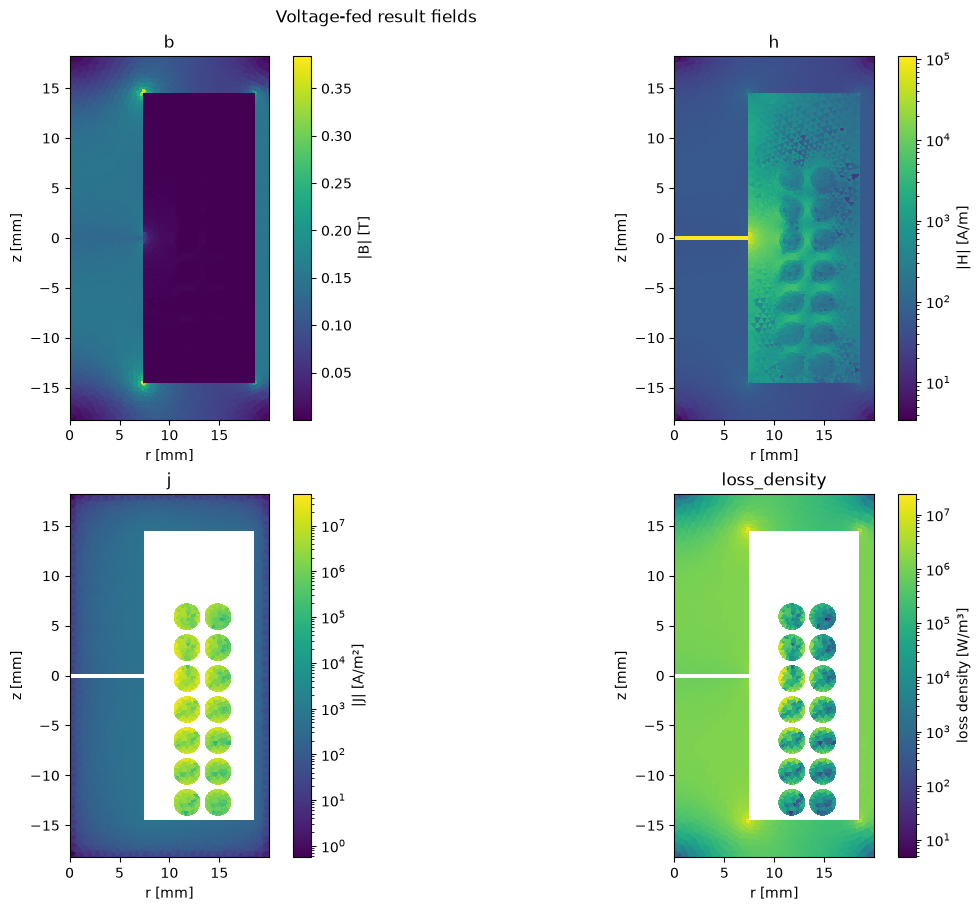

In [18]:
physical_fields = (
    fem.PhysicalField.B,
    fem.PhysicalField.H,
    fem.PhysicalField.J,
    fem.PhysicalField.LOSS_DENSITY,
)
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for axis, physical_field in zip(axes.flat, physical_fields):
    color_scale = (
        "log"
        if physical_field in {
            fem.PhysicalField.H,
            fem.PhysicalField.J,
            fem.PhysicalField.LOSS_DENSITY,
        }
        else "linear"
    )
    voltage_result.plot_physical_field(
        physical_field,
        ax=axis,
        color_scale=color_scale,
    )
    axis.set_title(physical_field.value)
fig.suptitle("Voltage-fed result fields")
plt.show()